<a href="https://colab.research.google.com/github/24f3003058/DL-GenAI/blob/main/Week1/LinearRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear regression using pytorch



In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [2]:
torch.__version__

'2.11.0+cu130'

In [3]:

print(torch.cuda.is_available())

True


In [4]:
#cuda version
print(torch.version.cuda)

13.0


In [5]:
#GPU Device
torch.cuda.get_device_name(0)

'Tesla T4'

In [6]:
#defining data
weight=0.8
bias=0.1

start=0
end=1
step=0.01
X=torch.arange(start,end,step).unsqueeze(dim=1)
y= weight*X + bias

print(f"X(first 10):{y[:10].flatten()}")
print(f"y(first 10 ):{y[:10].flatten()}")
print(X.shape,y.shape)

X(first 10):tensor([0.1000, 0.1080, 0.1160, 0.1240, 0.1320, 0.1400, 0.1480, 0.1560, 0.1640,
        0.1720])
y(first 10 ):tensor([0.1000, 0.1080, 0.1160, 0.1240, 0.1320, 0.1400, 0.1480, 0.1560, 0.1640,
        0.1720])
torch.Size([100, 1]) torch.Size([100, 1])


In [7]:
train_split=int(0.8 *len(X))
X_train,y_train=X[:train_split],y[:train_split]
X_test,y_test=X[train_split:],y[train_split:]

print(len(X_train),len(y_train))
print(len(X_test),len(y_test))

assert len(X_train) +len(X_test) == len(X)

80 80
20 20


In [8]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset=TensorDataset(X_train,y_train)
test_dataset=TensorDataset(X_test,y_test)

BATCH_SIZE=8
NUM_WORKERS=0

train_dataloader =DataLoader(dataset=train_dataset,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS)
test_dataloader=DataLoader(dataset=train_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)

print(len(train_dataloader),len(test_dataloader),BATCH_SIZE,len(train_dataset),len(test_dataset))


10 10 8 80 20


In [9]:
for batch_x, batch_y in train_dataloader:
  print(batch_x.shape,batch_y.shape)
  print("Batch x",batch_x)
  print("Batch y",batch_y)

torch.Size([8, 1]) torch.Size([8, 1])
Batch x tensor([[0.5000],
        [0.3300],
        [0.1800],
        [0.6200],
        [0.0100],
        [0.6900],
        [0.3900],
        [0.7100]])
Batch y tensor([[0.5000],
        [0.3640],
        [0.2440],
        [0.5960],
        [0.1080],
        [0.6520],
        [0.4120],
        [0.6680]])
torch.Size([8, 1]) torch.Size([8, 1])
Batch x tensor([[0.6300],
        [0.7200],
        [0.6500],
        [0.1900],
        [0.0800],
        [0.4700],
        [0.5800],
        [0.4800]])
Batch y tensor([[0.6040],
        [0.6760],
        [0.6200],
        [0.2520],
        [0.1640],
        [0.4760],
        [0.5640],
        [0.4840]])
torch.Size([8, 1]) torch.Size([8, 1])
Batch x tensor([[0.2900],
        [0.7800],
        [0.0500],
        [0.5300],
        [0.4500],
        [0.0200],
        [0.0700],
        [0.5600]])
Batch y tensor([[0.3320],
        [0.7240],
        [0.1400],
        [0.5240],
        [0.4600],
        [0.1160],
     

In [10]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  plt.figure(figsize=(10,7))
  plt.scatter(train_data,train_labels,c='green',s=25,alpha=0.5,label='Training data',marker='o')
  plt.scatter(test_data,test_labels,c='blue',s=15,alpha=0.7,label='Testing data',marker='s')

  if predictions is not None:
    plt.scatter(test_data,predictions ,c='red',s=25,alpha=0.8,marker='^')
  plt.xlabel("Input features(x)",fontsize=12)
  plt.ylabel("Target values(y)",fontsize=12)
  plt.title("Linear regression")
  plt.legend(fontsize=11)
  plt.grid(True,alpha=0.3)
  plt.tight_layout()


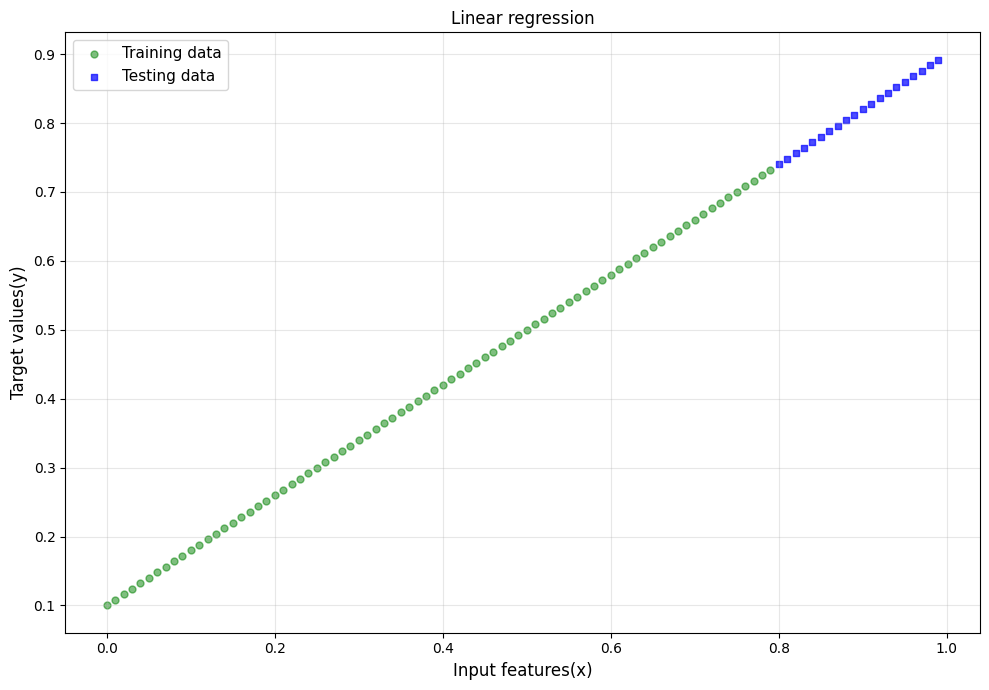

In [11]:
plot_predictions()

In [12]:
import torch.nn as nn
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weights=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)
    self.bias=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)

  def forward(self,x:torch.Tensor)->torch.Tensor:
    return self.weights * x +self.bias

model=LinearRegressionModel()
x=torch.tensor([[2.0],[3.0],[4.0]])
x, x.shape
y_pred=model(x)
print(y_pred)

tensor([[1.8874],
        [2.4777],
        [3.0680]], grad_fn=<AddBackward0>)


* Custom loss function

In [13]:
class MeanAbsoluteError(nn.Module):
  def __init__(self):
    super().__init__()

  def forward(self, predictions:torch.Tensor, targets:torch.Tensor)->torch.Tensor:
    absolute_errors=torch.abs(predictions -targets)
    return torch.mean(absolute_errors)

class HuberLoss(nn.Module):
  def __init__(self, delta:float=1.0):
    super().__init__()
    self.delta =delta

  def forward(self,predictions:torch.Tensor,targets:torch.Tensor)->torch.Tensor:
    # residuals
    residuals=predictions-targets
    abs_residuals =torch.abs(residuals)

    #apply huber loss
    quadratic_mask =abs_residuals <=self.delta
    linear_mask=abs_residuals >self.delta
    quadratic_loss=0.5 *residuals**2
    linear_loss=self.delta*abs_residuals

    quadratic_loss=0.5 *residuals **2
    linear_loss=self.delta*abs_residuals -0.5*self.delta**2

    loss=quadratic_loss*quadratic_mask + linear_mask*linear_loss
    loss=torch.where(abs_residuals<=self.delta, 0.5*residuals**2, self.delta*abs_residuals -0.5*self.delta**2)
    return torch.mean(loss)

custom_mae_loss=MeanAbsoluteError()
huber_loss=HuberLoss(delta=1.0)

print("Custom loss functions initialized")
print("custom MAE loss: ",custom_mae_loss)
print("Huber loss delta: ",huber_loss)
sample_predictions=torch.tensor([1.,2.,3.])
sample_targets=torch.tensor([1.1,1.2,4.2])

print(nn.L1Loss()(sample_predictions,sample_targets))
print(custom_mae_loss(sample_predictions,sample_targets))
print(huber_loss(sample_predictions,sample_targets))

Custom loss functions initialized
custom MAE loss:  MeanAbsoluteError()
Huber loss delta:  HuberLoss()
tensor(0.7000)
tensor(0.7000)
tensor(0.3417)


In [14]:
sample_predictions=torch.tensor([1.,2.,3.])
sample_targets=torch.tensor([1.2,3.5,3.3])

print(nn.L1Loss()(sample_predictions,sample_targets))
print(custom_mae_loss(sample_predictions,sample_targets))
print(huber_loss(sample_predictions,sample_targets))

tensor(0.6667)
tensor(0.6667)
tensor(0.3550)


# Linear Regression in Pytorch:Training Loop

In [15]:
import torch
torch.manual_seed(42)

model_0=LinearRegressionModel()

list(model_0.parameters())



[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [16]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [17]:
with torch.inference_mode():
  y_preds=model_0(X_test)

In [18]:
print(len(X_test),len(y_preds))
print(y_preds)

20 20
tensor([[0.3982],
        [0.4015],
        [0.4049],
        [0.4083],
        [0.4116],
        [0.4150],
        [0.4184],
        [0.4217],
        [0.4251],
        [0.4285],
        [0.4318],
        [0.4352],
        [0.4386],
        [0.4419],
        [0.4453],
        [0.4487],
        [0.4520],
        [0.4554],
        [0.4588],
        [0.4621]])


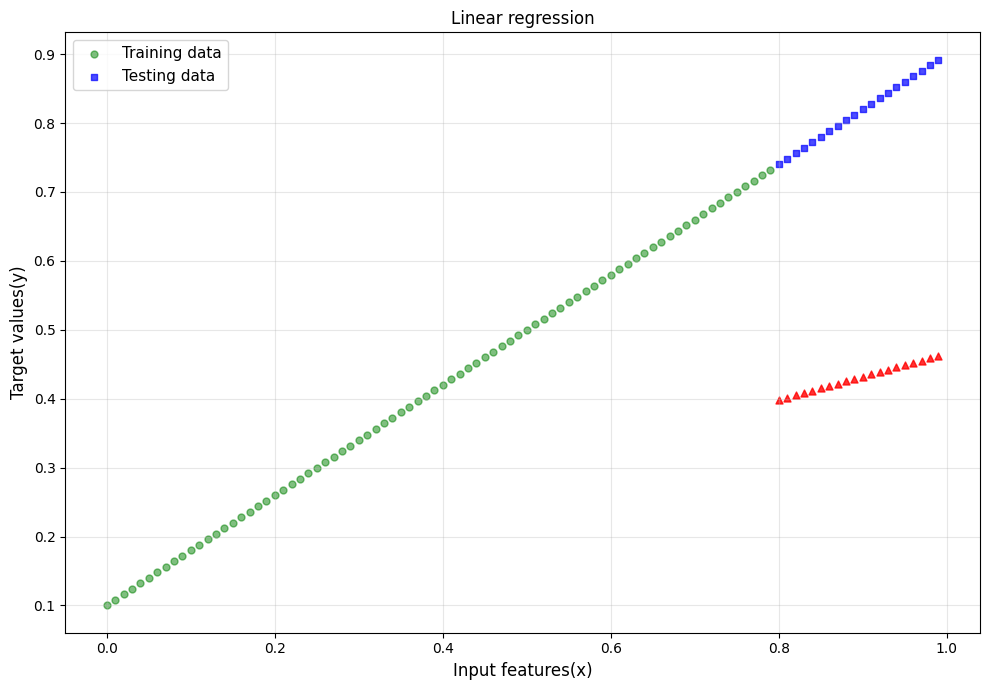

In [19]:
plot_predictions(predictions=y_preds)

In [21]:
loss_fn=nn.L1Loss()

optimizer=torch.optim.SGD(
    params=model_0.parameters(),
    lr=0.001
)

print(optimizer)
print(optimizer.param_groups[0]['lr'])

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)
0.001


In [22]:
print(len(list(model_0.parameters())))

2


In [24]:
epochs=100
for epoch in range(epochs):
  model_0.train()
  y_pred=model_0(X_train)

  loss=loss_fn(y_pred,y_train)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()


In [27]:
model_0.eval()
with torch.inference_mode():
  test_pred=model_0(X_test)

  test_loss=loss_fn(test_pred,y_test)
  if epoch %10 ==0:
    epoch_count.append(loss.detach().numpy)
    train_loss_values.append(loss.detach().numpy)
    print(epoch,loss,test_loss)

In [35]:
torch.manual_seed(42)
EPOCHS=350
PRINT_INTERVAL=20

#initialization of var for loss curves
train_loss_values=[]
test_loss_values=[]
epoch_count=[]

print("training progress")

for epoch in range(EPOCHS):
  model_0.train()
  epoch_train_loss=0.0
  num_train_batches=0
  for batch_X,batch_y in train_dataloader:
    y_pred=model_0(batch_X)
    batch_loss=loss_fn(y_pred,batch_y)
    optimizer.zero_grad()
    batch_loss.backward()
    optimizer.step()
    epoch_train_loss+=batch_loss.item()
    num_train_batches+=1


avg_train_loss=epoch_train_loss/num_train_batches
model_0.eval()
epoch_test_loss=0.0
num_test_batches=0

with torch.inference_mode():
  for batch_X,batch_y in test_dataloader:
    test_pred=model_0(batch_X)
    batch_test_loss=loss_fn(test_pred,batch_y)
    epoch_test_loss+=batch_test_loss.item()
    num_test_batches+=1
avg_test_loss=epoch_test_loss / num_test_batches

if epoch % PRINT_INTERVAL ==0:
  epoch_count.append(epoch)
  train_loss_values.append(avg_train_loss)
  test_loss_values.append(avg_test_loss)

  print(f"Epoch: {epoch:3d} | Train Loss: {avg_train_loss:.6f} | Test Loss: {avg_test_loss:.6f}")

print("training completes")
print(avg_train_loss,avg_test_loss)

training progress
training completes
0.0005706537514925003 0.0004753819666802883


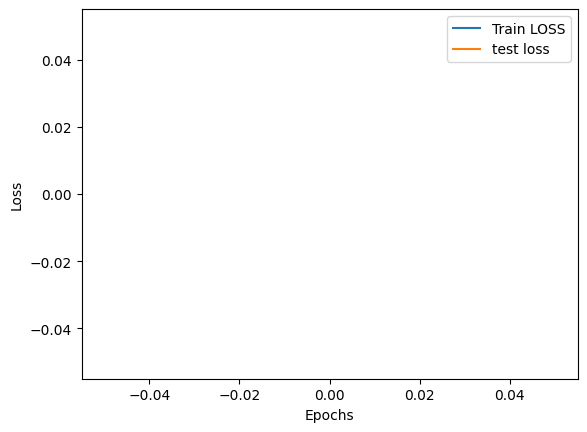

In [37]:
plt.plot(epoch_count,train_loss_values,label="Train LOSS" )
plt.plot(epoch_count, test_loss_values,label='test loss')
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

In [38]:
# Analyze learned parameters compared to ground truth values
print("Parameter Learning Analysis:")
print("=" * 50)

learned_params = model_0.state_dict()
print("Learned Parameters:")
for param_name, param_value in learned_params.items():
    print(f"  {param_name}: {param_value.item():.6f}")

print("\nGround Truth Parameters:")
print(f"  weights: {weight:.6f}")
print(f"  bias: {bias:.6f}")

print("\nParameter Recovery Analysis:")
weight_error = abs(learned_params['weights'].item() - weight)
bias_error = abs(learned_params['bias'].item() - bias)
print(f"  Weight Error: {weight_error:.6f}")
print(f"  Bias Error: {bias_error:.6f}")
print(f"  Total Absolute Error: {weight_error + bias_error:.6f}")

# Assess convergence quality
if weight_error < 0.01 and bias_error < 0.01:
    print("\n✓ Excellent parameter recovery achieved!")
elif weight_error < 0.05 and bias_error < 0.05:
    print("\n✓ Good parameter recovery achieved!")
else:
    print("\n⚠ Parameter recovery may require additional training or hyperparameter tuning.")

Parameter Learning Analysis:
Learned Parameters:
  weights: 0.800546
  bias: 0.100260

Ground Truth Parameters:
  weights: 0.800000
  bias: 0.100000

Parameter Recovery Analysis:
  Weight Error: 0.000546
  Bias Error: 0.000260
  Total Absolute Error: 0.000806

✓ Excellent parameter recovery achieved!
